# Estado del arte: árboles penalizados, gradiente potenciado transparente, gradiente potenciado monótono y un modelo de fundación frente a la tarjeta de puntaje

**Pregunta:** ¿Cuál de los retadores actuales de una tarjeta de puntaje WoE gana su lugar en 9.000 tarjetas reservadas de Taiwán cuando se ponderan juntos el orden, la calibración y la legibilidad, y cambia la respuesta en una muestra pequeña?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 a 05 de este tema
- **Tiempo de lectura:** unos 70 minutos

## Objetivos

Al terminar este notebook puedes:

- nombrar a los retadores actuales de una tarjeta de puntaje WoE en puntuación de crédito (árboles penalizados, refuerzo explicable, gradiente potenciado monótono, un modelo de fundación tabular), qué afirma cada uno y la fuente de la afirmación;
- ejecutar el motor sobre los ocho modelos de la escalera, reconstruidos desde sus curvas y tablas versionadas, con el AUC, el chi cuadrado sobre grados, la prueba de nivel y el protocolo de retadores, y contrastar el motor con scikit-learn como referencia independiente;
- abrir los componentes de caja de vidrio de los modelos versionados: las reglas y su estabilidad, las funciones de forma y las restricciones monótonas;
- leer qué hizo la calibración isotónica a cada retador, y qué cambia en una muestra pequeña.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import riskvalidation as rv
from sklearn.metrics import brier_score_loss, roc_auc_score

from riskvalidation.ml.challenger import grade_disagreement, paired_brier_bootstrap
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_hosmer_lemeshow, pd_jeffreys
from riskvalidation.validation.discrimination import auc_with_variance, disc_auc, disc_ks
from riskvalidation.validation.ml import challenger_brier

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "scikit-learn"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
scikit-learn 1.9.1


## Datos

La comparación lee cinco archivos versionados del caso C01 (PD de tarjetas de crédito minoristas):

- `data/derived/C01/holdout.json`: la escalera en las 9.000 tarjetas reservadas de Taiwán (archivo de tarjetas de crédito de Taiwán de UCI, Yeh, 2009; dueño: UCI Machine Learning Repository; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients): curvas ROC y CAP, grados, tramos de confiabilidad antes y después de calibrar, una muestra de 50 tarjetas puntuada por dos modelos y la batería de pruebas.
- `data/derived/C01/models-taiwan.json`: lo que aprendió cada modelo (reglas, funciones de forma, restricciones, mapas de calibración).
- `data/derived/C01/small-sample.json`: las mismas tarjetas puntuadas por modelos ajustados con solo 2.000 filas.
- `data/derived/C01/german-twin.json` y `data/derived/C01/models-german.json`: los datos de crédito alemanes Statlog (1.000 registros; UCI; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data), una muestra reservada de 300 registros puntuada por la escalera y por el modelo de fundación tabular TabPFN.

La siguiente celda carga los cinco archivos e imprime la escalera. El notebook fija `scikit-learn` como implementación de referencia independiente del AUC y del puntaje de Brier; los modelos mismos (árboles penalizados, máquina de refuerzo, árboles potenciados, TabPFN) los ajustó la cadena de cálculo sobre datos crudos que viven fuera del repositorio.

In [2]:
# Cargar los archivos versionados del caso C01: la escalera, los modelos ajustados y los casos de pocos datos
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
derived = ROOT / "data" / "derived" / "C01"
files = ("holdout.json", "models-taiwan.json", "small-sample.json", "german-twin.json", "models-german.json")
holdout, models, small, twin, models_german = [json.loads((derived / n).read_text(encoding="utf-8")) for n in files]
tests, rungs = holdout["tests"], holdout["outputs"]["rungs"]
ladder = [m["id"] for m in holdout["model"]]
details = {m["id"]: m["details"] for m in models["model"]}
policy = rv.default_policy()
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
print("modelos de la escalera:", ladder)
print("calculado por riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

modelos de la escalera: ['P0-constant', 'P0-single', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm', 'P4-xgboost']
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### El protocolo de la comparación

Cada retador se juzga sobre las mismas 9.000 tarjetas con la misma batería, de modo que una diferencia es una propiedad del modelo y no de la muestra. Deciden cuatro mediciones, y cada una tiene su herramienta en el motor. **Orden**: el AUC y, para dos modelos puntuados sobre las mismas tarjetas, la prueba de DeLong pareada del notebook 03 (DeLong, DeLong y Clarke-Pearson, 1988). **Ajuste por grado**: el chi cuadrado sobre los grados de la escala maestra (BCBS, 2005). **Nivel**: la prueba de Jeffreys de una cola sobre toda la muestra reservada. **Protocolo de retadores**: el remuestreo pareado del motor de la diferencia de Brier y la proporción de tarjetas que cambian de grado entre dos modelos. Las 9.000 tarjetas no están en el repositorio, pero sí la curva CAP, la tabla de grados y los tramos de confiabilidad de cada modelo, así que la celda reconstruye, para cada uno de los ocho modelos, un vector de 9.000 valores de riesgo y resultados desde los 100 escalones CAP (90 tarjetas cada uno) y ejecuta `auc_with_variance` y `disc_ks` sobre él. El AUC y su semiancho de 95% vuelven con el KS; la figura los dibuja junto al AUC que versionó la cadena de cálculo para las mismas tarjetas.

P0-constant AUC, semiancho, KS: 0.511 0.0143 0.0396
P0-single AUC, semiancho, KS: 0.6994 0.0145 0.3573
P1-scorecard AUC, semiancho, KS: 0.7586 0.0127 0.3956
P2a-l1 AUC, semiancho, KS: 0.7586 0.0127 0.3956
P2b-pltr AUC, semiancho, KS: 0.775 0.0121 0.4202
P3-ebm AUC, semiancho, KS: 0.7753 0.012 0.4249
P4-lightgbm AUC, semiancho, KS: 0.7778 0.0119 0.4249
P4-xgboost AUC, semiancho, KS: 0.7765 0.012 0.4235
tarjetas reconstruidas: 9000
ganancia de AUC sobre la tarjeta de puntaje: {'P2a-l1': -0.0, 'P2b-pltr': 0.0163, 'P3-ebm': 0.0167, 'P4-lightgbm': 0.0191, 'P4-xgboost': 0.0178}


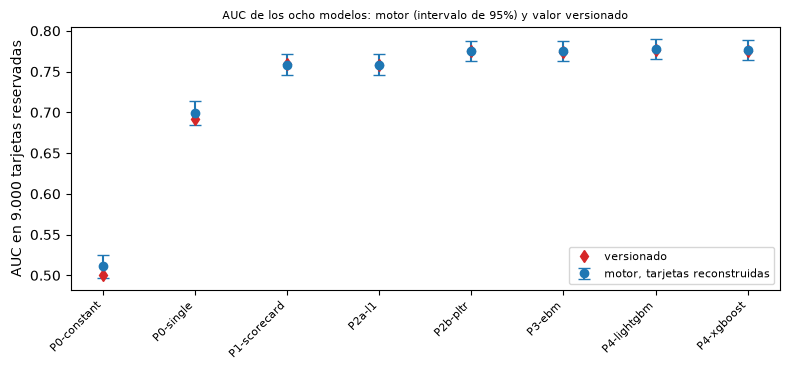

In [3]:
# Reconstruir 9000 tarjetas desde los escalones CAP de cada modelo y ejecutar el AUC, su varianza y el KS del motor
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
vectors, engine = {}, {}
for rung in ladder:
    per_slice = np.rint(np.diff(np.array(rungs[rung]["cap"]["defaults"])) * n_defaults).astype(int)
    size = n_cards // len(per_slice)
    risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
    flags = np.concatenate([np.r_[np.ones(d), np.zeros(size - d)] for d in per_slice])
    value, variance, _, _ = auc_with_variance(risk, flags)
    half = 1.96 * variance ** 0.5
    ks = disc_ks(risk, flags, policy=policy, model_id=rung)
    vectors[rung], engine[rung] = (risk, flags), (value, half, ks.metric)
    print(rung, "AUC, semiancho, KS:", round(value, 4), round(half, 4), round(ks.metric, 4))
committed = {t["model_id"]: t["metric"] for t in tests if t["test_id"] == "disc.auc" and t["segment"] == "portfolio"}
base = engine["P1-scorecard"][0]
gains = {r: round(engine[r][0] - base, 4) for r in ladder[3:]}
print("tarjetas reconstruidas:", n_cards)
print("ganancia de AUC sobre la tarjeta de puntaje:", gains)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(range(len(ladder)), [engine[r][0] for r in ladder], yerr=[engine[r][1] for r in ladder], fmt="o",
            capsize=4, label="motor, tarjetas reconstruidas")
ax.plot(range(len(ladder)), [committed[r] for r in ladder], "d", color="tab:red", label="versionado")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC en 9.000 tarjetas reservadas")
ax.set_title("AUC de los ocho modelos: motor (intervalo de 95%) y valor versionado", fontsize=8)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

El motor ubica juntas a la tarjeta de puntaje y a la regresión logística penalizada en 0,7586, a los árboles penalizados, la máquina de refuerzo y los dos modelos de árboles potenciados más arriba, en 0,775 a 0,7778, y a la línea base de una variable en 0,6994. Una ganancia de 0,016 a 0,019 puntos de AUC para los modelos más ricos es el tamaño que informan los benchmarks de la siguiente sección, y es menor que el semiancho de 95% de cerca de 0,012 de cada estimación, así que los intervalos se traslapan. Dos artefactos de la reconstrucción se ven en la figura: el modelo de una variable queda sobre su 0,6917 versionado, y el modelo constante en 0,511 donde el AUC verdadero es 0,5. En ambos muchas tarjetas comparten una PD, y cortar un bloque de empates en rebanadas hace que el vector reconstruido ordene tarjetas que el modelo no puede ordenar. Para modelos con muchos puntajes distintos los rombos rojos caen sobre los puntos azules.

### Ajuste por grado y nivel

Orden y calibración son propiedades separadas. El chi cuadrado sobre grados toma las tarjetas, los incumplimientos y la PD media de cada grado y rechaza cuando algún grado se aleja de su PD en cualquier dirección. La prueba de Jeffreys toma toda la muestra reservada y rechaza solo cuando los incumplimientos exceden lo que admite la PD promedio. La celda ejecuta ambas sobre la tabla de grados de cada modelo y dibuja el valor p del chi cuadrado, pintado con la luz que da el motor.

P0-constant chi cuadrado sobre grados, p, luz: 0.9942 verde
   prueba de nivel, p de Jeffreys: 0.496
P0-single chi cuadrado sobre grados, p, luz: 0.5982 verde
   prueba de nivel, p de Jeffreys: 0.264
P1-scorecard chi cuadrado sobre grados, p, luz: 0.0264 ámbar
   prueba de nivel, p de Jeffreys: 0.31
P2a-l1 chi cuadrado sobre grados, p, luz: 0.0405 ámbar
   prueba de nivel, p de Jeffreys: 0.314
P2b-pltr chi cuadrado sobre grados, p, luz: 0.4641 verde
   prueba de nivel, p de Jeffreys: 0.307
P3-ebm chi cuadrado sobre grados, p, luz: 0.0 roja
   prueba de nivel, p de Jeffreys: 0.778
P4-lightgbm chi cuadrado sobre grados, p, luz: 0.0007 roja
   prueba de nivel, p de Jeffreys: 0.82
P4-xgboost chi cuadrado sobre grados, p, luz: 0.0 roja
   prueba de nivel, p de Jeffreys: 0.836


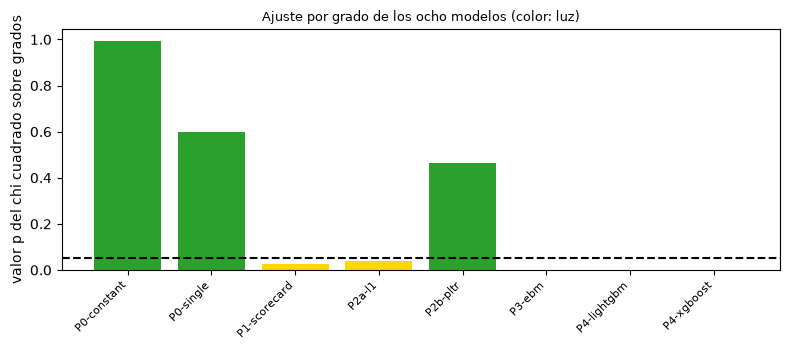

In [4]:
# El chi cuadrado sobre grados y la prueba de nivel del motor para cada modelo, desde su tabla de grados versionada
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, rung in enumerate(ladder):
    grades = [g for g in rungs[rung]["grades"] if g["n"] > 0]
    n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
    kw = dict(policy=policy, model_id=rung, segment="portfolio")
    chi = pd_chi2_grades(n_g, d_g, pd_g, **kw)
    level = pd_jeffreys(sum(n_g), sum(d_g), sum(n * p for n, p in zip(n_g, pd_g)) / sum(n_g), **kw)
    ax.bar(k, chi.p_value, color=colors[chi.light.value])
    print(rung, "chi cuadrado sobre grados, p, luz:", round(chi.p_value, 4), LIGHT[chi.light.value])
    print("   prueba de nivel, p de Jeffreys:", round(level.p_value, 3))
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("valor p del chi cuadrado sobre grados")
ax.set_title("Ajuste por grado de los ocho modelos (color: luz)", fontsize=9)
fig.tight_layout()
plt.show()

El chi cuadrado sobre grados es verde para el modelo constante (0,9942), la línea base de una variable (0,5982) y los árboles penalizados (0,4641), ámbar para la tarjeta de puntaje (0,0264) y la regresión logística penalizada (0,0405), y rojo para la máquina de refuerzo (0,0), LightGBM (0,0007) y XGBoost (0,0). La prueba de nivel es verde para los ocho (p entre 0,264 y 0,836). Los modelos que mejor ordenan tienen entonces el promedio correcto y el ajuste por grado incorrecto, y los árboles penalizados son el único modelo más rico que conserva ambos. Un mejor ordenador no es un mejor calibrado, y por eso el producto recalibra a sus retadores (paso 6 del estado del arte).

### El protocolo de retadores del motor

El módulo de aprendizaje automático del motor compara a un retador con el campeón sobre las mismas tarjetas. `paired_brier_bootstrap` remuestrea las tarjetas, calcula el puntaje de Brier de ambas PD en cada remuestreo y devuelve la diferencia con un intervalo de 95%; `challenger_brier` la envuelve como un resultado de prueba; `grade_disagreement` devuelve la proporción de tarjetas cuyo grado difiere en dos peldaños o más entre las dos PD. Solo 50 tarjetas llevan a la vez la PD de la tarjeta de puntaje y el puntaje de la máquina de refuerzo, así que la celda ejecuta el protocolo sobre ellas, con 2.000 remuestreos con semilla.

In [5]:
# Protocolo de retadores del motor en las 50 tarjetas: remuestreo pareado de Brier y tarjetas que cambian de grado
y50 = np.array(holdout["outputs"]["sample"]["targets"])
p_card = np.array(holdout["outputs"]["sample"]["scorecard_pd"])
p_ebm = 1.0 / (1.0 + np.exp(-np.array(holdout["outputs"]["sample"]["ebm_logit"])))
paired = paired_brier_bootstrap(p_card, p_ebm, y50, n_boot=2000, seed=7)
verdict = challenger_brier("P3-ebm", paired)
edges = np.array([g["hi"] for g in rungs["P1-scorecard"]["grades"]][:-1])
print("diferencia pareada de Brier, IC 95%:", round(paired.diff, 4), round(paired.lo, 4), round(paired.hi, 4))
print("valor p de la prueba de remuestreo y luz:", verdict.p_value, LIGHT[verdict.light.value])
print("proporción de tarjetas que cambia dos grados:", round(grade_disagreement(p_card, p_ebm, edges, 2), 3))

diferencia pareada de Brier, IC 95%: -0.0039 -0.0165 0.0084
valor p de la prueba de remuestreo y luz: None verde
proporción de tarjetas que cambia dos grados: 0.02


La diferencia de Brier entre la máquina de refuerzo y la tarjeta de puntaje es -0,0039, con un intervalo de -0,0165 a 0,0084 que incluye el cero: con 50 tarjetas no se muestra que el retador pronostique mejor. El resultado de la prueba no trae valor p (la política por defecto no tiene umbral para la comparación de Brier, así que la luz es verde por defecto y la evidencia es el intervalo), y solo 0,02 de las tarjetas, una de 50, cambia dos grados entre las dos PD. El protocolo funciona; la muestra es demasiado pequeña para usarlo en una decisión, cosa que los autores de los benchmarks dirían primero.

## Estado del arte

### La evidencia de los benchmarks

La investigación de este producto (dossier 04, sección B.4) leyó los benchmarks de puntuación de crédito. Cuatro hallazgos enmarcan la comparación, cada uno con su fuente:

| Fuente | Diseño | Hallazgo relevante aquí |
|---|---|---|
| Baesens et al. (2003), https://doi.org/10.1057/palgrave.jors.2601545 | 8 conjuntos de datos reales de crédito, AUC y exactitud con pruebas de significancia | las máquinas de vectores de soporte y las redes neuronales funcionan muy bien, y la regresión logística simple y el análisis discriminante lineal también funcionan muy bien |
| Lessmann, Baesens, Seow y Thomas (2015), https://doi.org/10.1016/j.ejor.2015.05.030 | 41 clasificadores, 8 conjuntos minoristas, seis medidas | varios clasificadores superan significativamente a la regresión logística, en especial los conjuntos heterogéneos; el bosque aleatorio es el punto de comparación mínimo recomendado; informar al menos el AUC, el Gini parcial y el puntaje de Brier |
| Gunnarsson et al. (2021), https://doi.org/10.1016/j.ejor.2021.03.006 | perceptrón multicapa y red de creencia profunda contra regresión logística, árboles, bosque aleatorio y XGBoost | XGBoost es el mejor método, y las redes profundas no superan a sus contrapartes menos profundas |
| Grinsztajn, Oyallon y Varoquaux (2022), https://arxiv.org/abs/2207.08815 | 45 conjuntos tabulares generales (no específicos de crédito) | los modelos de árboles siguen siendo el estado del arte en datos de tamaño medio, de unas 10.000 muestras |

La síntesis que sigue la escalera del producto: los conjuntos de árboles superan a la regresión logística simple en la mayoría de los benchmarks minoristas, por unos pocos puntos de AUC; la regresión logística sobre WoE bien agrupado sigue siendo competitiva; la interpretabilidad puede recuperarse con modelos restringidos o de caja de vidrio, los retadores naturales de un modelo de PD regulado; y la calibración es separada de la discriminación.

### Una implementación independiente de las medidas

Antes de confiar en una comparación se contrastan las medidas mismas con una implementación que el producto no escribió. La biblioteca fijada `scikit-learn` implementa `roc_auc_score` y `brier_score_loss`. La celda las ejecuta sobre los mismos vectores que el motor, el AUC sobre las tarjetas reconstruidas desde los escalones CAP y el puntaje de Brier sobre las tarjetas reconstruidas desde los tramos de confiabilidad (cada tarjeta toma la PD media de su tramo, cada tramo su número observado de incumplimientos), y dibuja los dos conjuntos de valores uno contra otro para los ocho modelos.

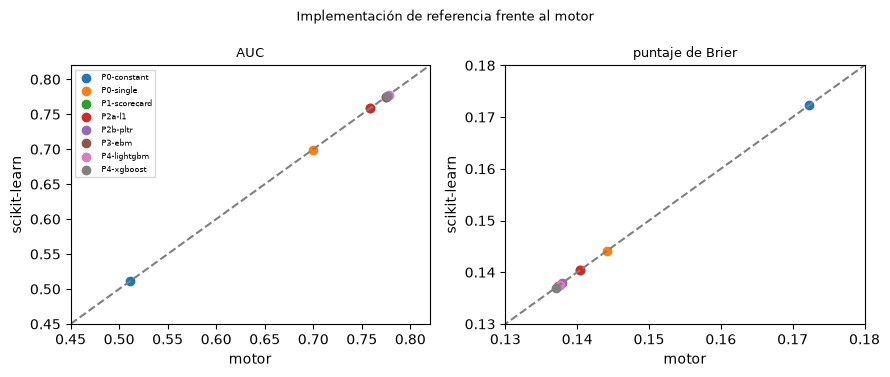

mayor diferencia de AUC y de Brier entre ambos: 0.0 0.0


In [6]:
# scikit-learn sobre las mismas tarjetas: AUC en las reconstruidas, Brier en las reconstruidas desde los tramos
gap_auc = gap_brier = 0.0
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))
for rung in ladder:
    risk, flags = vectors[rung]
    bins_ = rungs[rung]["reliability"]
    pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
    hits = [int(round(b["dr"] * b["n"])) for b in bins_]
    flags_pd = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
    reference = (roc_auc_score(flags, risk), brier_score_loss(flags_pd, pd_cards))
    ours = (engine[rung][0], pd_brier(flags_pd, pd_cards, policy=policy, model_id=rung, segment="portfolio").metric)
    gap_auc, gap_brier = max(gap_auc, abs(reference[0] - ours[0])), max(gap_brier, abs(reference[1] - ours[1]))
    left.scatter(ours[0], reference[0], label=rung)
    right.scatter(ours[1], reference[1])
for ax, name in ((left, "AUC"), (right, "puntaje de Brier")):
    ax.plot([0.1, 1], [0.1, 1], color="gray", linestyle="--")
    ax.set_xlabel("motor")
    ax.set_ylabel("scikit-learn")
    ax.set_title(name, fontsize=9)
left.set_xlim(0.45, 0.82)
left.set_ylim(0.45, 0.82)
right.set_xlim(0.13, 0.18)
right.set_ylim(0.13, 0.18)
left.legend(fontsize=6)
fig.suptitle("Implementación de referencia frente al motor", fontsize=9)
fig.tight_layout()
plt.show()
print("mayor diferencia de AUC y de Brier entre ambos:", round(gap_auc, 6), round(gap_brier, 6))

Los puntos de los ocho modelos caen sobre la diagonal en ambos paneles, y la mayor diferencia entre las dos implementaciones es menor que una millonésima para el AUC y para el puntaje de Brier (ambas imprimen 0,0 con seis decimales). Las medidas que usa el notebook no son entonces un artefacto de una implementación; lo que depende del motor es el vector reconstruido y la política, que las celdas anteriores declaran. El panel de Brier es también la primera vista de cuán poco difieren los modelos como pronósticos: los ocho quedan entre 0,136 y 0,173.

### Árboles penalizados (PLTR) y la regresión logística penalizada

Dumitrescu, Hue, Hurlin y Tokpavi (2022, https://doi.org/10.1016/j.ejor.2021.06.053) proponen la **regresión logística de árboles penalizada**: se hacen crecer árboles de decisión cortos, cada camino de la raíz a un nodo se convierte en una regla binaria (como "`PAY_0 <= 1.5`"), y las reglas entran en una regresión logística con una penalización L1 que conserva pocas. El resumen de la investigación informa que supera significativamente a la regresión logística y es competitiva con un bosque aleatorio conservando la legibilidad de un modelo logístico. El peldaño P2b del producto sigue ese diseño con árboles de scikit-learn y `LogisticRegression`, con su propia extracción de reglas; el peldaño P2a es la regresión logística L1 simple sobre las variables WoE. La celda dibuja las 12 reglas con los mayores coeficientes entre las que conservó la penalización, e imprime cuántas reglas candidatas hubo y cuán estable es la selección entre 20 remuestreos (el índice de Jaccard medio de los conjuntos elegidos, 1 para conjuntos idénticos).

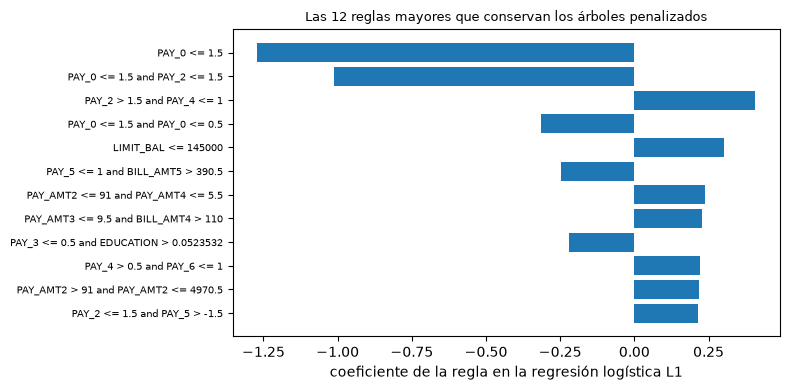

reglas candidatas y reglas conservadas: 449 101
Jaccard de los conjuntos elegidos, media, mín.: 0.411 0.367


In [7]:
# Las reglas que conservan los árboles penalizados (P2b): los 12 mayores coeficientes y la estabilidad de la selección
pltr = details["P2b-pltr"]
top = sorted(pltr["selected_rules"], key=lambda r: -abs(r["coefficient"]))[:12]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([r["rule"][:44] for r in top][::-1], [r["coefficient"] for r in top][::-1], color="tab:blue")
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("coeficiente de la regla en la regresión logística L1")
ax.set_title("Las 12 reglas mayores que conservan los árboles penalizados", fontsize=9)
fig.tight_layout()
plt.show()
stability = pltr["stability"]
print("reglas candidatas y reglas conservadas:", pltr["n_candidate_rules"], len(pltr["selected_rules"]))
mean_j, min_j = stability["jaccard_mean"], stability["jaccard_min"]
print("Jaccard de los conjuntos elegidos, media, mín.:", round(mean_j, 3), round(min_j, 3))

La mayor regla es `PAY_0 <= 1.5` con un coeficiente de cerca de -1,27, el mismo estado de pago que lleva a la tarjeta de puntaje, y la siguiente, `PAY_0 <= 1.5 and PAY_2 <= 1.5`, también negativa: las reglas son conjunciones cortas de a lo más dos condiciones, de modo que cada una se lee por sí sola. De 449 reglas candidatas la penalización conservó 101, y la selección no es estable: el índice de Jaccard medio entre remuestreos es 0,411 y su mínimo 0,367, así que solo cerca de dos quintos de las reglas elegidas se comparten entre dos remuestreos. Las reglas son una buena lectura del modelo y una mala definición de él, pues otra muestra daría otra lista con un desempeño similar.

### Refuerzo explicable (EBM y GA2M)

El modelo aditivo generalizado con interacciones de a pares (GA2M; Lou, Caruana, Gehrke y Hooker, 2013, https://doi.org/10.1145/2487575.2487579) y su implementación potenciada, la máquina de refuerzo explicable (Nori, Jenkins, Koch y Caruana, 2019, https://arxiv.org/abs/1909.09223), modelan el logaritmo de las probabilidades relativas como una suma de funciones de una variable y unos pocos términos de a pares,

$$g(\mathbb{E}[y]) = \beta_0 + \sum_j f_j(x_j) + \sum_{(i,j)} f_{ij}(x_i, x_j),$$

con $g$ el enlace logit y cada $f_j$ aprendida por gradiente potenciado cíclico con una tasa de aprendizaje muy baja. La consecuencia para el crédito es que un EBM es una tarjeta de puntaje potenciada: cada $f_j$ puede leerse como una tabla de puntos y los códigos de razón de los efectos principales son exactos. El ajuste versionado exporta sus términos, y la celda dibuja la función de forma del límite de crédito y del último estado de pago junto a la contribución de la tarjeta de puntaje en sus propios tramos, $\beta_j\,\mathrm{WoE}_{j,b}$ (notebook 01), ambas desplazadas para empezar en cero porque las constantes aditivas viven en el intercepto.

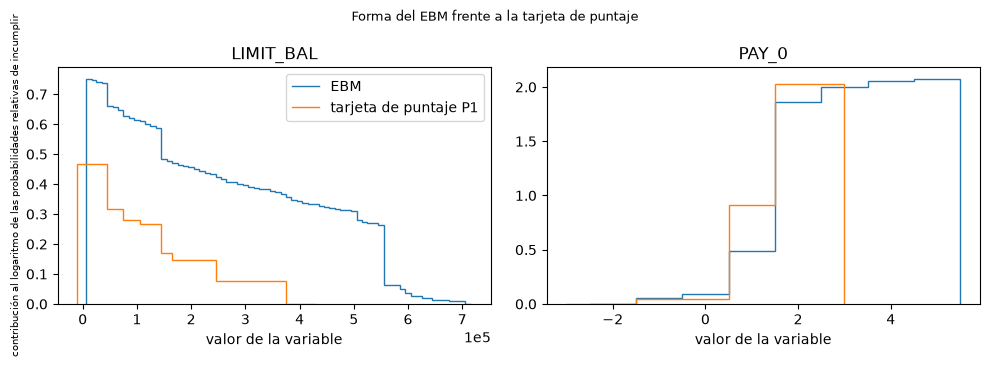

In [8]:
# Las funciones de forma del EBM frente a la contribución de la tarjeta de puntaje en sus tramos, para dos variables
export = details["P3-ebm"]["export"]
terms = {t["name"]: t for t in export["terms"] if len(t["features"]) == 1}
cuts = {f["name"]: f["levels"][0]["cuts"] for f in export["features"] if "cuts" in f["levels"][0]}
card = details["P1-scorecard"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    rows = [r for r in card["points_table"] if r["feature"] == name and r["count"] > 0]
    card_steps = np.array([card["coefficients"][name] * r["woe"] for r in rows])
    series = [(cuts[name], np.array(terms[name]["scores"][1:-1]), "EBM"),
              (card["bins"][name]["splits"], card_steps, "tarjeta de puntaje P1")]
    for c, scores, label in series:
        c = np.array(c, dtype=float)
        pad = max(float(np.diff(c).mean()) if len(c) > 1 else 1.0, 1.0)
        ax.stairs(scores - scores.min(), np.r_[c[0] - pad, c, c[-1] + pad], label=label)
    ax.set_title(name)
    ax.set_xlabel("valor de la variable")
axes[0].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set_ylabel("contribución al logaritmo de las probabilidades relativas de incumplir", fontsize=7)
axes[0].legend()
fig.suptitle("Forma del EBM frente a la tarjeta de puntaje", fontsize=9)
fig.tight_layout()
plt.show()

Ambos modelos dicen lo mismo del estado de pago: casi ninguna contribución para las tarjetas que pagaron a tiempo, un alza cerca de 0,5 a 1,5 meses de atraso y una meseta de cerca de dos unidades de logaritmo de probabilidades relativas más allá. El EBM es más suave, con escalones finos donde la tarjeta de puntaje tiene 4 u 8 tramos, y para el límite de crédito cae de modo sostenido y termina cerca de cero, una forma que los ocho tramos de la tarjeta de puntaje solo aproximan. Eso es lo que obtiene el producto de la versión potenciada: la misma lectura aditiva con una curva más fina. Las formas dicen también dónde la tarjeta de puntaje es gruesa y la máquina de refuerzo podría sobreajustar: el EBM pone sus propios puntos de corte en decenas de valores, y nada le prohíbe una curva no monótona.

### Gradiente potenciado monótono

Los árboles de gradiente potenciado (LightGBM, XGBoost, CatBoost) aceptan una restricción monótona por variable, la misma dirección que la tarjeta de puntaje impone con su agrupación. La documentación de cada motor declara las salvedades que registró la investigación: con los métodos de árbol `hist` o `approx`, las restricciones de XGBoost pueden eliminar candidatos de partición y dar árboles poco profundos (https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html); LightGBM ofrece los métodos `basic`, `intermediate` y `advanced`, de los cuales `basic` restringe de más las predicciones (https://lightgbm.readthedocs.io/en/latest/Parameters.html); y el `monotonize()` del EBM se aplica después del ajuste, un término a la vez. El ajuste versionado de LightGBM usa el método `advanced` con las mismas restricciones que la tarjeta de puntaje y guarda una revisión, la curva de dependencia parcial del modelo a lo largo de una grilla de cada variable restringida. La celda compara las restricciones con las de la tarjeta de puntaje, imprime la mayor violación hallada y dibuja dos curvas.

restricciones iguales a las de la tarjeta de puntaje, mayor violación: True 0.0


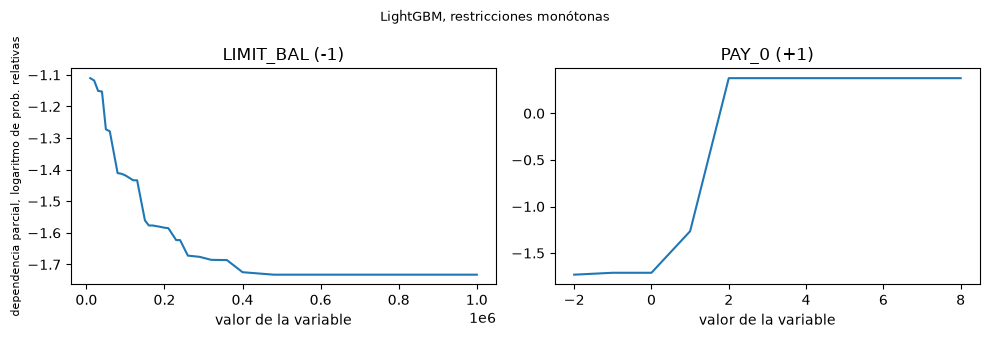

In [9]:
# Restricciones monótonas de LightGBM frente a las de la tarjeta de puntaje, la revisión guardada y dos curvas
lgbm = details["P4-lightgbm"]
wanted = {v["name"]: v["monotone"] for v in models["fit"]["features"]}
check = lgbm["monotonicity"]
worst = max(f["max_violation"] for f in check["features"].values())
print("restricciones iguales a las de la tarjeta de puntaje, mayor violación:", lgbm["constraints"] == wanted, worst)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    f = check["features"][name]
    ax.plot(f["grid"], f["pdp"])
    ax.set_title(f"{name} ({f['direction']:+d})")
    ax.set_xlabel("valor de la variable")
axes[0].set_ylabel("dependencia parcial, logaritmo de prob. relativas", fontsize=8)
fig.suptitle("LightGBM, restricciones monótonas", fontsize=9)
fig.tight_layout()
plt.show()

Las restricciones de LightGBM son iguales a las de la tarjeta de puntaje (la comparación imprime True) y la mayor violación hallada a lo largo de la grilla es 0,0: la curva del límite de crédito nunca sube y la del estado de pago nunca baja. El producto obtiene así la dirección que el regulador lee en una tarjeta de puntaje desde un modelo de árboles potenciados, con 94 árboles. Lo que la figura no muestra es dónde la restricción cuesta orden, y el AUC de 0,7778 frente a 0,7586 dice que cuesta poco.

### Calibración después del orden

Discriminación y calibración son propiedades separadas, y valen dos advertencias de la investigación. Corregir un desbalance de clases remuestreando (submuestreo o sobremuestreo aleatorio, SMOTE) produce modelos fuertemente descalibrados, con la probabilidad de la clase minoritaria sobrestimada y sin un AUC mayor (van den Goorbergh, van Smeden, Timmerman y Van Calster, 2022, https://doi.org/10.1093/jamia/ocac093); cuando una muestra se balancea por diseño, el intercepto debe corregirse por la probabilidad a priori (King y Zeng, 2001, https://doi.org/10.1093/oxfordjournals.pan.a004868). C01 no remuestrea nada: su tasa de incumplimiento es 22%. Lo que hace el producto es ajustar un **mapa de calibración posterior** con una parte de tarjetas que ni el ajuste ni la prueba han visto, la regresión isotónica (Zadrozny y Elkan, 2002, https://doi.org/10.1145/775047.775151), una función escalonada monótona que no puede reordenar las tarjetas. El artefacto guarda los tramos de confiabilidad antes del mapa y después de él. La celda dibuja ambos para la máquina de refuerzo junto al mapa mismo, e imprime el error de calibración esperado, $\mathrm{ECE} = \sum_b (n_b/N)\,|\overline{\mathrm{PD}}_b - \mathrm{DR}_b|$, de los tres retadores calibrados antes y después de él.

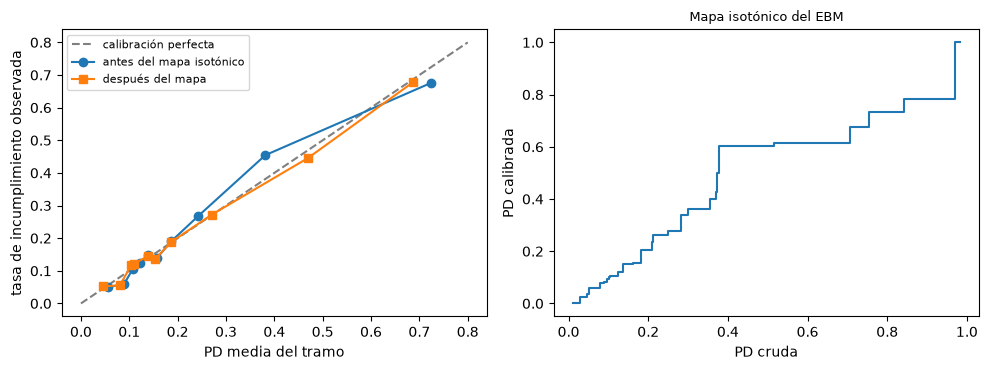

P3-ebm ECE antes y después del mapa: 0.0218 0.0118
P4-lightgbm ECE antes y después del mapa: 0.0121 0.0134
P4-xgboost ECE antes y después del mapa: 0.0131 0.0124


In [10]:
# El mapa isotónico del EBM, la confiabilidad de su PD cruda y calibrada, y el ECE de cada retador
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
raw, cal = rungs["P3-ebm"]["reliability_raw"], rungs["P3-ebm"]["reliability"]
left.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="calibración perfecta")
left.plot([b["pd"] for b in raw], [b["dr"] for b in raw], marker="o", label="antes del mapa isotónico")
left.plot([b["pd"] for b in cal], [b["dr"] for b in cal], marker="s", label="después del mapa")
left.set_xlabel("PD media del tramo")
left.set_ylabel("tasa de incumplimiento observada")
left.legend(fontsize=8)
mapping = next(m["calibration"] for m in models["model"] if m["id"] == "P3-ebm")
right.step(mapping["x"], mapping["y"], where="post")
right.set_xlabel("PD cruda")
right.set_ylabel("PD calibrada")
right.set_title("Mapa isotónico del EBM", fontsize=9)
fig.tight_layout()
plt.show()
for rung in ("P3-ebm", "P4-lightgbm", "P4-xgboost"):
    scores = []
    for key in ("reliability_raw", "reliability"):
        bins_ = rungs[rung][key]
        pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
        hits = [int(round(b["dr"] * b["n"])) for b in bins_]
        flags = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
        scores.append(pd_ece(flags, pd_cards, bins=10, policy=policy, model_id=rung, segment="portfolio").metric)
    print(rung, "ECE antes y después del mapa:", round(scores[0], 4), round(scores[1], 4))

Antes del mapa, la máquina de refuerzo subestima el tramo cercano a 0,38 y sobrestima el superior, con un ECE de 0,0218; después de él, los puntos quedan sobre la diagonal y el ECE es 0,0118. El mapa es una escalera plana en gran parte del rango de PD cruda, entre 0,4 y 0,5 donde mantiene un valor, que es como un mapa isotónico agrupa tarjetas que el modelo no pudo separar. No ayuda a todos los modelos: LightGBM ya estaba cerca de la diagonal (0,0121) y termina algo peor (0,0134), y XGBoost mejora de 0,0131 a 0,0124. La recalibración repara una descalibración visible y agrega ruido cuando no la hay, y su parte debe ser lo bastante grande: el mismo chi cuadrado sobre grados sigue rojo para los tres después de ella.

### Pocos datos y el modelo de fundación

Los modelos de fundación tabulares son la frontera abierta de la investigación, más fuertes con pocos datos (Hollmann et al., 2025, https://doi.org/10.1038/s41586-024-08328-6): TabPFN predice por aprendizaje en contexto y no entrena nada por conjunto de datos. Su licencia es parte de la evidencia. Según la investigación (leída del README del proyecto, https://github.com/PriorLabs/TabPFN, el 2026-10-04) el código es Apache-2.0 mientras los pesos se licencian por versión: los de v2 bajo la Prior Labs License v1.1 (Apache 2.0 más una cláusula de atribución), los de versiones posteriores bajo una licencia no comercial que permite investigación y evaluación interna pero no uso en producción. El producto lo lleva entonces como un **retador de investigación** opcional (peldaño P5), presente solo donde su extra está instalado. La evidencia específica de crédito hallada es un resumen de congreso con resultados preliminares y sin números (NO VERIFICADO más allá del resumen). El gemelo alemán tiene 1.000 registros y una muestra reservada de 300, el caso de pocos datos. La celda reconstruye los 300 registros alemanes y las 9.000 tarjetas de Taiwán puntuadas por modelos ajustados con 2.000 filas desde sus escalones CAP, ejecuta el AUC del motor sobre cada peldaño, imprime el motor y la versión de P5 y dibuja los tres conjuntos de evaluación lado a lado.

motor y versión de P5: tabpfn 9.1.0
AUC del motor en el gemelo alemán: {'P0-constant': 0.48, 'P0-single': 0.715, 'P1-scorecard': 0.788, 'P2a-l1': 0.791, 'P2b-pltr': 0.786, 'P3-ebm': 0.785, 'P4-lightgbm': 0.778, 'P5-tabpfn': 0.779}
AUC del motor, modelos de Taiwán ajustados con 2000 filas: {'P0-constant': 0.511, 'P0-single': 0.701, 'P1-scorecard': 0.752, 'P2a-l1': 0.751, 'P2b-pltr': 0.753, 'P3-ebm': 0.766, 'P4-lightgbm': 0.761}


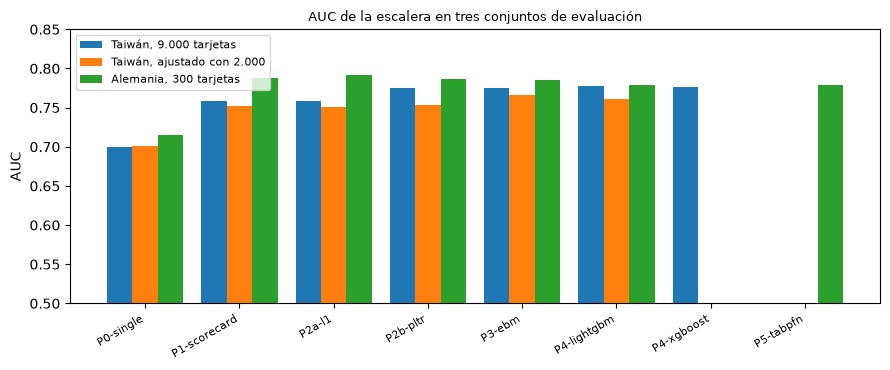

In [11]:
# El AUC del motor en los dos casos de pocos datos, reconstruidos desde sus escalones CAP
sets = (("small", small), ("twin", twin))
auc_small = {}
for name, doc in sets:
    n_all, d_all = doc["outputs"]["n"], doc["outputs"]["defaults"]
    for rung in [m["id"] for m in doc["model"]]:
        out = doc["outputs"]["rungs"][rung]
        per_slice = np.rint(np.diff(np.array(out["cap"]["defaults"])) * d_all).astype(int)
        size = n_all // len(per_slice)
        risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
        flags = np.concatenate([np.r_[np.ones(d), np.zeros(max(size - d, 0))] for d in per_slice])
        auc_small[(name, rung)] = disc_auc(risk, flags, policy=policy, model_id=rung).metric
p5 = next(m for m in models_german["model"] if m["id"] == "P5-tabpfn")
print("motor y versión de P5:", p5["engine"], p5["engine_version"])
twin_auc = {r: round(a, 3) for (n, r), a in auc_small.items() if n == "twin"}
small_auc = {r: round(a, 3) for (n, r), a in auc_small.items() if n == "small"}
print("AUC del motor en el gemelo alemán:", twin_auc)
print("AUC del motor, modelos de Taiwán ajustados con 2000 filas:", small_auc)
fig, ax = plt.subplots(figsize=(9, 3.8))
names_sets = ["Taiwán, 9.000 tarjetas", "Taiwán, ajustado con 2.000", "Alemania, 300 tarjetas"]
shown = ladder[1:] + ["P5-tabpfn"]
for k, (label, name) in enumerate(zip(names_sets, ("big", "small", "twin"))):
    values = [engine[r][0] if name == "big" and r in engine else auc_small.get((name, r), np.nan) for r in shown]
    ax.bar(np.arange(len(shown)) + (k - 1) * 0.27, values, width=0.27, label=label)
ax.set_xticks(range(len(shown)), shown, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("AUC")
ax.set_title("AUC de la escalera en tres conjuntos de evaluación", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Inferencia de rechazados: reparar una muestra que eligió la política anterior (M-35)

Todos los retadores anteriores se ajustaron sobre tarjetas que un banco ya había otorgado. Una tarjeta de puntaje de admisión tiene
el mismo problema en forma más aguda: aprende de los solicitantes que aceptó una política heredada, nunca de los que rechazó, y luego
se usa sobre todos los que postulan. La inferencia de rechazados es la familia de métodos que intenta repararlo con los solicitantes
rechazados, cuyo resultado nunca se observa. El módulo `c01_reject` del pipeline implementa el conjunto estándar sobre un mismo
aprendiz logístico penalizado, de modo que solo cambia el tratamiento de los rechazados: aumentación por el inverso de la
probabilidad de aceptación (Banasik y Crook 2007), un corte duro, parcelación con y sin un factor de prudencia de dos (Siddiqi 2017)
y aumentación difusa, junto al modelo de solo aceptados (el sesgo que hay que reparar) y al oráculo que ve todos los resultados (la
referencia que ningún prestamista puede ajustar).

Los métodos solo pueden juzgarse donde se conoce el resultado de los rechazados, así que la celda siguiente sortea una población así:
1.000 solicitantes con un plazo, un monto, una edad y un estado de cuenta corriente, y un incumplimiento sorteado de una ley logística
conocida. Una política heredada acepta luego al mejor 60 % según un puntaje que suma la visión privada del analista sobre el
resultado, de fuerza `kappa`: 0 es una política ciega al resultado una vez conocidas las variables, 1 una señal privada fuerte. Hand
y Henley (1993) y Crook y Banasik (2004) sostienen que ninguna inferencia de rechazados repara una selección hecha con información
que el modelo no ve; esta corrida lo mide, con 40 repeticiones por política, sobre una población de aceptación total de 300
solicitantes reservada en cada repetición.

In [ ]:
# Sortear una población etiquetada y correr los peldaños de inferencia de rechazados bajo cuatro políticas
from pipeline.cases import c01_reject as reject

rng = np.random.default_rng(20261030)
n = 1000
duration = rng.gamma(4.0, 5.0, n)
amount = rng.lognormal(7.8, 0.8, n)
age = rng.uniform(19, 75, n)
checking = rng.choice(["none", "negative", "low", "high"], n, p=[0.4, 0.27, 0.27, 0.06])
effect = {"none": -1.1, "negative": 0.6, "low": 0.2, "high": -0.6}
logit = -1.2 + 0.035 * (duration - 20) + 0.25 * np.log(amount / 2500) - 0.02 * (age - 35)
logit = logit + np.vectorize(effect.get)(checking)
target = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
people = pd.DataFrame({"duration": duration, "amount": amount, "age": age, "checking": checking, "target": target})
features = ("duration", "amount", "age", "checking")
study = reject.run(people, features, ("checking",), seed=6, reps=40, population="drawn in notebook 02/06")
label = "tasa de incumplimiento de la población, los aceptados y los rechazados"
for regime in study["regimes"]:
    rates = regime["default_rate"]
    shares = f"{rates['population']:.3f}, {rates['accepted']:.3f}, {rates['rejected']:.3f}"
    print(f"{regime['id']:9s} kappa {regime['kappa']:.2f} | {label}: {shares}")


La tasa de incumplimiento de la población es 0,190 en todas las políticas, como debe ser: la política cambia a quién se
acepta, no quién incumple. Con la política ciega los aceptados incumplen a 0,135 y los rechazados a 0,272, así que la política opera
solo sobre las variables. Con la señal privada la brecha se abre a 0,057 contra 0,389 en la fuerza moderada y a 0,012 contra 0,457
en la fuerte: la cartera aceptada se reduce a una población casi sin incumplimientos, que es la muestra de la que aprende el modelo
siguiente. La figura muestra lo que eso le hace a la tasa de incumplimiento que cada peldaño predice para toda la población.

In [ ]:
# Dibujar el sesgo medio de la tasa predicha sobre la población de aceptación total, por peldaño y política
kappas = [g["kappa"] for g in study["regimes"]]
bias_pp = {}
for rung in reject.RUNGS:
    bias_pp[rung] = [100 * next(r for r in g["rungs"] if r["id"] == rung)["bias"]["mean"] for g in study["regimes"]]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for rung, bias in bias_pp.items():
    style = "--" if rung in ("oracle", "accepted-only") else "-"
    ax.plot(kappas, bias, style, marker="o", label=rung)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("fuerza de la señal privada del analista, kappa")
ax.set_ylabel("tasa de incumplimiento predicha menos observada (pp)")
ax.set_title("Inferencia de rechazados contra el sesgo de un modelo de solo aceptados")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()
for rung in ("oracle", "accepted-only", "parcelling-prudent"):
    print(f"{rung:19s}", ", ".join(f"{b:+.2f}" for b in bias_pp[rung]))


La línea discontinua de solo aceptados cae desde casi cero con la política ciega a -7,65, -13,00 y -17,94 puntos a medida que
la señal privada se fortalece: el modelo aprende la tasa de incumplimiento de la cartera aceptada y la lleva a todos. El oráculo
queda en cero en todas las fuerzas. La aumentación, el corte duro, la parcelación simple y la aumentación difusa quedan sobre la
línea de solo aceptados: cada una infiere los resultados de los rechazados desde el mismo modelo de solo aceptados, así que reproduce
su sesgo. Solo la parcelación prudente se aparta, porque el factor de dos es un supuesto sobre los rechazados que los datos no
contienen; lo paga con la política ciega, donde sobrestima la tasa de incumplimiento en 9,69 puntos mientras el modelo de solo
aceptados se desviaba en 0,76.

In [ ]:
# La reducción del sesgo y el cambio de AUC de cada peldaño con la política moderada, y las tres hipótesis
moderate = next(g for g in study["regimes"] if g["id"] == reject.PRIMARY)
label = "reducción"
for r in moderate["rungs"][2:]:
    red, auc = r["reduction"], r["auc_vs_accepted_only"]
    cut = f"{red['value']:+.3f} [{red['lo']:+.3f}, {red['hi']:+.3f}]"
    gain = f"{auc['mean']:+.4f} [{auc['lo']:+.4f}, {auc['hi']:+.4f}]"
    print(f"{r['id']:19s} {label} {cut} | AUC {gain}")
for h in study["hypotheses"]:
    print(h["id"], h["outcome"]["es"])


Con la política moderada las hipótesis fijadas antes de la corrida se juzgan sobre estos números. El modelo de solo
aceptados subestima la tasa de incumplimiento (H1 se cumple). El mejor peldaño, la parcelación prudente, reduce el sesgo en 0,180 con
un intervalo de 0,150 a 0,211, bajo el 25 % que pide el plan, así que H2 no se cumple en esta población. Además ordena mejor que el
modelo de solo aceptados en 0,0512 de AUC, más que el 0,01 que hace esperar la literatura, así que H3 tampoco se cumple. La
aumentación ordena peor: sus pesos ponen el mayor énfasis en los pocos aceptados que se parecen a los rechazados.

In [ ]:
# El mismo estudio sobre los 1.000 solicitantes de German Credit, versionado por el horneado de C01 (100 repeticiones)
committed = twin["outputs"]["reject_inference"]
label = "reducción"
for g in committed["regimes"]:
    plain = next(r for r in g["rungs"] if r["id"] == "parcelling")["reduction"]["value"]
    prudent = next(r for r in g["rungs"] if r["id"] == "parcelling-prudent")["reduction"]["value"]
    print(f"{g['id']:9s} {label}: parcelling {plain:+.3f}, parcelling-prudent {prudent:+.3f}")
for h in committed["hypotheses"]:
    print(h["id"], h["outcome"]["es"])


El resultado versionado del producto corre el mismo módulo sobre los 1.000 solicitantes de los datos German Credit, cuyos
resultados se conocen todos, con 100 repeticiones. Su patrón es el medido arriba: la parcelación simple reduce el sesgo en 0,023 con
la política moderada y la prudente en 0,443, el único peldaño que alcanza el 25 % del plan, así que allí H2 se cumple; con la
política ciega la parcelación prudente multiplica el sesgo varias veces. El veredicto depende entonces de que el factor de prudencia
sea el correcto, algo que un prestamista no puede verificar sin los resultados de los rechazados, y ese es el punto de Hand y
Henley.

## Resultados

**Respuesta:** En 9.000 tarjetas reservadas de Taiwán los retadores más ricos ordenan mejor por unos pocos puntos de AUC, y ninguno gana cuando se pondera la calibración. El motor, ejecutado sobre las tarjetas reconstruidas desde las curvas versionadas, da un AUC de 0,7586 para la tarjeta de puntaje, 0,775 para los árboles penalizados, 0,7753 para la máquina de refuerzo, 0,7778 para LightGBM y 0,7765 para XGBoost, frente a 0,6994 para una variable: una ganancia de 0,016 a 0,019 puntos, con un semiancho de 95% de cerca de 0,012 en cada estimación. La tarjeta de puntaje empata con la regresión logística penalizada (0,7586). Por grado, el valor p del chi cuadrado es 0,0264 (ámbar) para la tarjeta de puntaje, 0,4641 (verde) para los árboles penalizados, y 0,0007 o 0,0 (rojo) para la máquina de refuerzo, LightGBM y XGBoost, mientras la prueba de nivel es verde para los ocho (0,31 a 0,836). El único retador que conserva la ganancia de orden y el ajuste es el de árboles penalizados, cuyas 101 reglas son inestables entre remuestreos (Jaccard medio 0,411). Los árboles potenciados monótonos conservan la dirección de la tarjeta de puntaje (mayor violación 0,0), y el mapa isotónico lleva el ECE de la máquina de refuerzo de 0,0218 a 0,0118 pero empeora el de LightGBM de 0,0121 a 0,0134.

Con pocos datos la ventaja de orden desaparece: en los 300 registros alemanes el motor da 0,788 para la tarjeta de puntaje, 0,791 para la regresión logística penalizada, 0,785 para la máquina de refuerzo, 0,778 para LightGBM y 0,779 para TabPFN, y los modelos de Taiwán ajustados con 2.000 filas están en 0,752 para la tarjeta de puntaje y 0,766 para la máquina de refuerzo. El modelo de fundación, con condiciones de licencia sobre sus pesos, no supera aquí a la tarjeta de puntaje. La referencia de scikit-learn coincide con el motor en el AUC y en el puntaje de Brier a menos de una millonésima (mayores diferencias 0,0 y 0,0).

Lo que este notebook no muestra: un reajuste de cualquier retador (los modelos los ajustó la cadena de cálculo con datos crudos, y los paquetes que los ajustan no están en el entorno de los notebooks), una prueba de DeLong pareada entre los retadores en las 9.000 tarjetas (los puntajes pareados no están versionados, solo las filas de la batería), y el mapa isotónico ajustado de nuevo con una parte de calibración.

La inferencia de rechazados (M-35), corrida en este notebook sobre 1.000 solicitantes cuyos resultados se conocen todos, no
repara una selección hecha con la señal privada del analista: con la política moderada el modelo de solo aceptados se desvía en
-13,00 puntos, y el mejor peldaño, la parcelación prudente, quita 0,180 de ese sesgo mientras los otros cuatro no quitan nada; sobre
los solicitantes de German Credit el producto mide 0,443 para el mismo peldaño, que descansa en un factor de prudencia que ningún
prestamista puede verificar.

## Resumen

- La investigación de este producto halló que los conjuntos de árboles superan a una regresión logística simple por unos pocos puntos de AUC en crédito minorista, que las variantes de caja de vidrio recuperan la interpretabilidad, que la calibración es separada del orden, y que los modelos de fundación tabulares son más fuertes con pocos datos bajo restricciones de licencia; la escalera versionada reproduce cada afirmación con sus propios datos.
- El AUC, el chi cuadrado sobre grados, la prueba de nivel y el protocolo pareado de retadores del motor ponen a todos los modelos en el mismo pie, y `scikit-learn` coincide con él en el AUC y el puntaje de Brier.
- Las cajas de vidrio pueden leerse: reglas y su inestabilidad, funciones de forma junto a las contribuciones de la tarjeta de puntaje, restricciones con una revisión guardada.
- Un mapa isotónico repara la descalibración de la máquina de refuerzo y agrega ruido a LightGBM; con 300 registros la ventaja de orden de los modelos más ricos desaparece.

**Qué probar a continuación.** Imprime los `reliability_raw` y `reliability` versionados de XGBoost junto a los de la máquina de refuerzo y mira qué tramos se mueven; luego continúa con el notebook 07, que mide lo que impone el protocolo a prueba de fuga de todo el tema.

- La inferencia de rechazados (M-35) repara una muestra de solo aceptados solo mediante un supuesto sobre los rechazados: la parcelación prudente redujo el sesgo en 0,180 aquí y en 0,443 sobre German Credit, y lo agrandó cuando la política era ciega al resultado.

## Referencias

- Baesens, B., Van Gestel, T., Viaene, S., Stepanova, M., Suykens, J. y Vanthienen, J. (2003), Journal of the Operational Research Society 54(6). https://doi.org/10.1057/palgrave.jors.2601545
- Lessmann, S., Baesens, B., Seow, H.-V. y Thomas, L. C. (2015), European Journal of Operational Research 247(1). https://doi.org/10.1016/j.ejor.2015.05.030
- Gunnarsson, B. R., vanden Broucke, S., Baesens, B., Oskarsdottir, M. y Lemahieu, W. (2021), Deep learning for credit scoring: do or don't?, European Journal of Operational Research 295(1). https://doi.org/10.1016/j.ejor.2021.03.006
- Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022), Why do tree-based models still outperform deep learning on typical tabular data?, NeurIPS 2022 Datasets and Benchmarks. https://arxiv.org/abs/2207.08815
- Dumitrescu, E., Hue, S., Hurlin, C. y Tokpavi, S. (2022), penalised logistic tree regression, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.053
- Lou, Y., Caruana, R., Gehrke, J. y Hooker, G. (2013), Accurate intelligible models with pairwise interactions, KDD 2013. https://doi.org/10.1145/2487575.2487579
- Nori, H., Jenkins, S., Koch, P. y Caruana, R. (2019), InterpretML: a unified framework for machine learning interpretability. https://arxiv.org/abs/1909.09223
- van den Goorbergh, R., van Smeden, M., Timmerman, D. y Van Calster, B. (2022), The harm of class imbalance corrections for risk prediction models, JAMIA 29(9). https://doi.org/10.1093/jamia/ocac093
- King, G. y Zeng, L. (2001), Logistic regression in rare events data, Political Analysis 9(2). https://doi.org/10.1093/oxfordjournals.pan.a004868
- Zadrozny, B. y Elkan, C. (2002), Transforming classifier scores into accurate multiclass probability estimates, KDD 2002. https://doi.org/10.1145/775047.775151
- Hollmann, N. et al. (2025), Accurate predictions on small data with a tabular foundation model, Nature 637. https://doi.org/10.1038/s41586-024-08328-6 ; las licencias de los pesos son las del README del proyecto, https://github.com/PriorLabs/TabPFN
- Documentación de XGBoost, restricciones monótonas. https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html ; documentación de LightGBM, parámetros. https://lightgbm.readthedocs.io/en/latest/Parameters.html
- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves, Biometrics 44(3). https://doi.org/10.2307/2531595
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Statlog German Credit Data, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

- Hand, D. J. y Henley, W. E. (1993), Can reject inference ever work?, IMA Journal of Mathematics Applied in Business and Industry 5(1), 45-55, https://doi.org/10.1093/imaman/5.1.45
- Crook, J. y Banasik, J. (2004), Does reject inference really improve the performance of application scoring models?, Journal of Banking and Finance 28(4), 857-874, https://doi.org/10.1016/j.jbankfin.2003.10.010
- Banasik, J. y Crook, J. (2007), Reject inference, augmentation, and sample selection, European Journal of Operational Research 183(3), 1582-1594, https://doi.org/10.1016/j.ejor.2006.06.072
- Siddiqi, N. (2017), Intelligent Credit Scoring, 2.ª edición, Wiley, capítulo sobre inferencia de rechazados, https://doi.org/10.1002/9781119282396